# Praktikum 3 - Regresi Harga Rumah dengan Keras

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/praktikum-3)

Kode utama mengikuti dua blok modul: (1) regresi data dummy `luas` → `harga`, lalu Tugas 4, dan (2) MLP 64-32-1 pada data Boston.

Catatan kompatibilitas Boston: `sklearn.datasets.load_boston` hanya memberi *warning* deprecation pada scikit-learn 1.0-1.1,
tetapi **dihapus sejak versi 1.2**. Pada scikit-learn 1.9.1 di `.venv`, `from sklearn.datasets import load_boston` menghasilkan
`ImportError`. Agar dataset tetap Boston Housing yang sama (506 baris, 13 fitur, target MEDV), fungsi `load_boston` dibuat ulang.
Fungsi ini membaca file asli StatLib CMU sesuai saran pesan error scikit-learn. Salinan file ada di `data/boston.txt`.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


## Bagian 1 - Data dummy (kode modul)

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
h_dummy = model.fit(X_train, y_train, epochs=100, verbose=0)
print('Loss epoch 1   :', round(h_dummy.history['loss'][0], 4))
print('Loss epoch 100 :', round(h_dummy.history['loss'][-1], 4))

# Evaluasi
print("Prediksi:", model.predict(X_test, verbose=0))

Loss epoch 1   : 1.0661
Loss epoch 100 : 0.6002
Prediksi: [[-0.0161034]]


In [3]:
pred_harga = scaler.inverse_transform(model.predict(X_test, verbose=0))   # scaler terakhir di-fit pada harga
print('Data uji (skala standar):', X_test.ravel(), '-> target', y_test.ravel())
print('Prediksi harga:', pred_harga.ravel().round(1), ' | harga aktual:', scaler.inverse_transform(y_test).ravel())

Data uji (skala standar): [-0.70710678] -> target [-0.70710678]
Prediksi harga: [697.7]  | harga aktual: [600.]


Pada modul, `scaler` yang sama di-*fit* dua kali. Setelah baris `y = scaler.fit_transform(y)`, parameternya adalah parameter `harga`.
Karena itu `inverse_transform` di atas hanya benar untuk prediksi harga, bukan untuk `luas`. Dengan hanya 4 data latih dan 100 epoch,
model belum konvergen: loss masih turun dan prediksinya belum mendekati harga aktual. Hal ini dibahas pada Tugas 4.

## Tugas 4

* Ubah learning rate.
* Bandingkan hasil loss.

Data, split, arsitektur, dan 100 epoch sama dengan blok modul. Hanya learning rate Adam yang divariasikan: 1e-4, 1e-3 (default),
1e-2, dan 1e-1. Setiap learning rate diulang pada 5 seed bobot awal karena data latihnya hanya 4 titik.

In [4]:
import matplotlib.pyplot as plt
lr_rows, lr_curves = [], {}
for lr in [1e-4, 1e-3, 1e-2, 1e-1]:
    for seed in [0, 1, 2, 3, 42]:
        tf.keras.utils.set_random_seed(seed)
        m = tf.keras.Sequential([tf.keras.layers.Input(shape=(1,)),
                                 tf.keras.layers.Dense(10, activation='relu'), tf.keras.layers.Dense(1)])
        m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
        h = m.fit(X_train, y_train, epochs=100, verbose=0)
        test_mse = m.evaluate(X_test, y_test, verbose=0)
        lr_rows.append({'learning_rate': lr, 'seed': seed, 'loss_epoch1': h.history['loss'][0],
                        'loss_epoch10': h.history['loss'][9], 'loss_epoch100': h.history['loss'][-1], 'test_mse': test_mse})
        if seed == 42: lr_curves[lr] = h.history['loss']
lr_df = pd.DataFrame(lr_rows)
lr_df.groupby('learning_rate')[['loss_epoch1', 'loss_epoch10', 'loss_epoch100', 'test_mse']].agg(['mean', 'std']).round(5)

loss_epoch1          loss_epoch10          loss_epoch100  \
                     mean      std         mean      std          mean   
learning_rate                                                            
0.0001            1.03562  0.42523      1.02699  0.42394       0.94559   
0.0010            1.03562  0.42523      0.95272  0.41244       0.44409   
0.0100            1.03562  0.42523      0.46073  0.30138       0.00207   
0.1000            1.03562  0.42523      0.06324  0.05897       0.00001   

                       test_mse           
                   std     mean      std  
learning_rate                             
0.0001         0.41110  0.52239  0.32245  
0.0010         0.28784  0.20733  0.18098  
0.0100         0.00120  0.02983  0.03551  
0.1000         0.00001  0.01062  0.01090

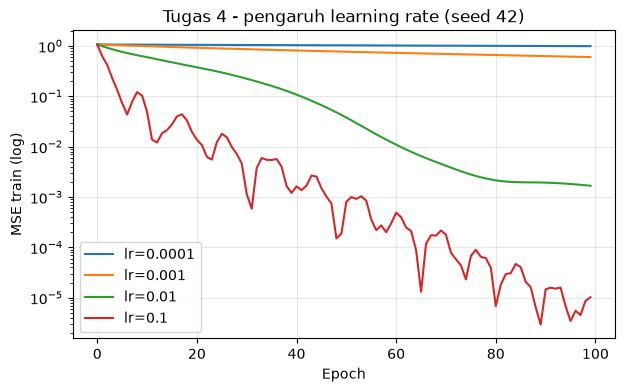

In [5]:
plt.figure(figsize=(7, 4))
for lr, c in lr_curves.items():
    plt.plot(c, label=f'lr={lr:g}')
plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('MSE train (log)'); plt.title('Tugas 4 - pengaruh learning rate (seed 42)')
plt.legend(); plt.grid(alpha=.3); plt.show()

## Analisis Tugas 4

Kode modul dengan learning rate default Adam (0,001) hanya menurunkan loss dari 1,066 ke 0,600 dalam 100 epoch. Prediksi harga untuk luas 60 m² masih 697,7, padahal nilai sebenarnya 600.

| Learning rate | Loss epoch 1 | Loss epoch 10 | Loss epoch 100 | MSE test |
| --- | --- | --- | --- | --- |
| 0,0001 | 1,036 | 1,027 | 0,946 | 0,522 |
| 0,001 (default) | 1,036 | 0,953 | 0,444 | 0,207 |
| 0,01 | 1,036 | 0,461 | 0,0021 | 0,030 |
| 0,1 | 1,036 | 0,063 | **0,00001** | **0,011** |

(rata-rata 5 seed; loss dalam skala standar)

* Learning rate adalah hyperparameter paling berpengaruh dalam pelatihan gradien (Bengio, 2012). Dengan 4 titik latih, setiap epoch hanya berisi satu langkah update, sehingga 100 epoch = 100 langkah. Dengan `lr = 1e-4`, 100 langkah praktis tidak menggerakkan bobot. Dengan `1e-3`, loss baru turun separuh.
* `lr = 0,01` dan `0,1` mencapai loss mendekati nol karena hubungan luas-harga pada data dummy linier sempurna (harga = 10 × luas). Pada data ini lr besar aman karena permukaan loss sederhana dan Adam menormalisasi besar langkah per parameter (Kingma & Ba, 2015).
* Kesimpulan ini **tidak** dapat digeneralisasi. Pada data nyata yang bising dan bermini-batch, lr terlalu besar menyebabkan osilasi atau divergensi. Smith (2017) menganjurkan *learning-rate range test* untuk mencari batas atas lr yang masih stabil. Selain itu, 1 titik uji (MSE test) terlalu sedikit untuk menilai generalisasi.

## Bagian 2 - MLP regresi data Boston (kode modul)

In [6]:
# Pengganti load_boston: memuat Boston Housing dari sumber aslinya (StatLib CMU), file sama dengan yang dibaca scikit-learn < 1.2.
import pandas as pd
from pathlib import Path
from types import SimpleNamespace

def load_boston(path='data/boston.txt', url='http://lib.stat.cmu.edu/datasets/boston'):
    source = path if Path(path).exists() else url
    raw = pd.read_csv(source, sep=r'\s+', skiprows=22, header=None)
    data = np.hstack([raw.values[::2, :], raw.values[1::2, :2]])
    target = raw.values[1::2, 2]
    names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
    return SimpleNamespace(data=data, target=target, feature_names=np.array(names))

(506, 13) (506,)


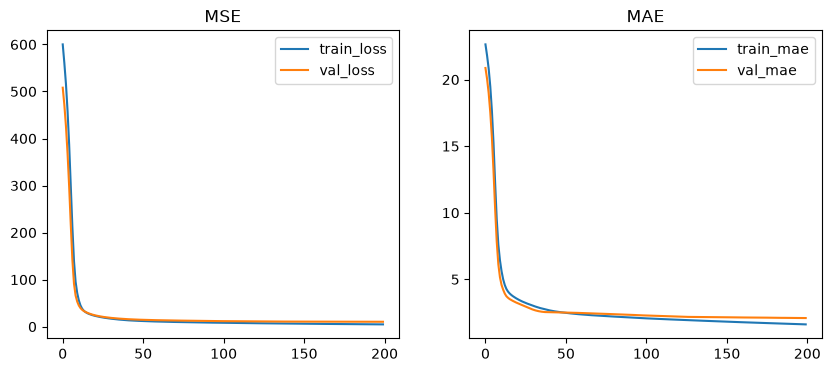

RMSE: 3.227051823251839


In [7]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
tf.keras.utils.set_random_seed(42)

# 1. Load
data = load_boston()
X = data.data; y = data.target
print(X.shape, y.shape)

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
Input(shape=(X_train.shape[1],)),
Dense(64, activation='relu'),
Dense(32, activation='relu'),
Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val, verbose=0)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

### Perbandingan dengan model lain

Untuk menilai MLP modul, model dibandingkan dengan regresi linier (OLS) dan Random Forest pada split yang sama (`random_state=42`).
Satuan RMSE dan MAE adalah ribu USD (MEDV).

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def score(name, p):
    return {'model': name, 'RMSE': np.sqrt(mean_squared_error(y_val, p)), 'MAE': mean_absolute_error(y_val, p), 'R2': r2_score(y_val, p)}

comparison = pd.DataFrame([
    score('Regresi linier (OLS)', LinearRegression().fit(X_train, y_train).predict(X_val)),
    score('Random Forest (500 pohon)', RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(X_train, y_train).predict(X_val)),
    score('MLP 64-32-1 (modul)', pred.ravel()),
]).set_index('model')
comparison.round(3)

,RMSE,MAE,R2
model,,,
Regresi linier (OLS),4.929,3.189,0.669
Random Forest (500 pohon),2.982,2.093,0.879
MLP 64-32-1 (modul),3.227,2.095,0.858


## Analisis Bagian 2

**Hasil MLP modul pada Boston Housing:** RMSE validasi **3,23** (ribu USD), MAE 2,10, R² 0,858. Pada kurva MSE, perhatikan selisih antara loss train dan validasi. Dengan hanya 404 sampel latih dan 200 epoch tanpa regularisasi, loss train terus turun lebih jauh daripada loss validasi.

| Model | RMSE | MAE | R² |
| --- | --- | --- | --- |
| Regresi linier (OLS) | 4,93 | 3,19 | 0,669 |
| **Random Forest** | **2,98** | **2,09** | **0,879** |
| MLP 64-32-1 (modul) | 3,23 | 2,10 | 0,858 |

* MLP jauh lebih baik daripada regresi linier (RMSE turun 35%). Hubungan harga dengan `LSTAT` dan `RM` tidak linier, dan data Boston aslinya dimodelkan Harrison & Rubinfeld (1978) dengan transformasi log dan kuadrat secara manual. MLP mempelajari bentuk tidak linier tersebut secara otomatis.
* Random Forest (Breiman, 2001) sedikit mengungguli MLP tanpa tuning. Hasil ini sejalan dengan studi benchmark Grinsztajn dkk. (2022): pada data tabular berukuran kecil-menengah, model berbasis pohon masih umumnya lebih baik daripada deep learning, karena data tabular memiliki fitur yang tidak informatif dan fungsi target yang tidak mulus.
* Catatan metodologi: modul men-*fit* `StandardScaler` pada seluruh data sebelum split. Kebocoran informasi ini kecil untuk standardisasi, tetapi praktik yang benar adalah *fit* hanya pada data train. Satu split 80:20 dengan 102 data validasi juga membuat RMSE masih bervariasi antar-split, sehingga perbandingan yang lebih kuat membutuhkan *k-fold cross validation*.

## Rujukan

1. Harrison, D., & Rubinfeld, D. L. (1978). Hedonic housing prices and the demand for clean air. *Journal of Environmental Economics and Management*, 5(1), 81-102. https://doi.org/10.1016/0095-0696(78)90006-2
2. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*. https://arxiv.org/abs/1412.6980
3. Bengio, Y. (2012). Practical recommendations for gradient-based training of deep architectures. Dalam *Neural Networks: Tricks of the Trade* (2nd ed., LNCS 7700, hlm. 437-478). Springer. https://doi.org/10.1007/978-3-642-35289-8_26
4. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32. https://doi.org/10.1023/A:1010933404324
5. Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems 35 (Datasets and Benchmarks Track)*.